In [1]:
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import ot_utils
import comparison_utils
from tqdm import tqdm
import math
import matplotlib.pyplot as plt
from itertools import combinations
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [2]:
# classification_aucs = np.zeros((8, 8))

# for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
#     self_matrix_1_file = f"../../medium_w2/w2_block_{i}_{i}.npy"
#     self_matrix_2_file = f"../../medium_w2/w2_block_{j}_{j}.npy"
#     off_diag_matrix_file = f"../../medium_w2/w2_block_{i}_{j}.npy"

#     big_matrix = ot_utils.combine_distance_blocks(
#         [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
#     )

#     labels = np.repeat([0, 1], 4000)

#     rel_reps = comparison_utils.relative_rep(
#         big_matrix, labels, num_classes=2, anchors_per_class=100, seed=42
#     )

#     y = np.r_[np.zeros(4000, dtype=int), np.ones(4000, dtype=int)]

#     # Train/test split (stratified)
#     X_train, X_test, y_train, y_test = train_test_split(
#         rel_reps, y, test_size=0.2, stratify=y, random_state=42
#     )

#     # MLP with 2 hidden layers, no scaling
#     mlp = MLPClassifier(
#         hidden_layer_sizes=(128, 64),  # two hidden layers
#         activation="relu",
#         solver="adam",
#         alpha=1e-4,  # L2 regularization
#         batch_size=256,
#         learning_rate_init=1e-3,
#         max_iter=200,
#         early_stopping=True,
#         n_iter_no_change=10,
#         random_state=42,
#         verbose=False,
#     )

#     # Hyperparameter search (kept small for speed; expand if needed)
#     param_grid = {
#         "hidden_layer_sizes": [(256, 128), (128, 64)],
#         "alpha": [1e-4, 1e-3, 1e-2],
#         "learning_rate_init": [1e-3, 3e-3, 1e-2],
#         "batch_size": [128, 256],
#     }

#     cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#     grid = GridSearchCV(
#         mlp,
#         param_grid=param_grid,
#         scoring="accuracy",  # or 'roc_auc'
#         cv=cv,
#         n_jobs=-1,
#         verbose=1,
#     )

#     grid.fit(X_train, y_train)

#     print("Best params:", grid.best_params_)
#     print("CV best score (mean acc):", grid.best_score_)

#     # Evaluate on held-out test set
#     best_model = grid.best_estimator_
#     y_pred = best_model.predict(X_test)

#     # print("\nTest set report:")
#     # print(classification_report(y_test, y_pred, digits=4))
#     # print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

#     # ROC-AUC
#     y_score = best_model.predict_proba(X_test)[:, 1]
#     classification_aucs[i, j] = roc_auc_score(y_test, y_score)
#     print("Test ROC-AUC:", classification_aucs[i, j])

In [3]:
# A = classification_aucs.copy()
# n = A.shape[0]

# # mask: keep only strict upper triangle (k=1), hide everything else
# mask = np.triu(np.ones_like(A, dtype=bool), k=1)
# plot_A = np.where(mask, A, np.nan)

# # color range: min non-zero to max over the visible (unmasked) cells
# vals = plot_A[~np.isnan(plot_A)]
# nonzero = vals[vals != 0]
# vmin, vmax = float(nonzero.min()), float(nonzero.max())

# fig, ax = plt.subplots(figsize=(6, 5))
# cmap = plt.get_cmap("viridis").copy()
# cmap.set_bad(color=(1, 1, 1, 0))  # transparent for masked cells

# im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# # axes and labels
# ax.set_xticks(range(n))
# ax.set_yticks(range(n))
# ax.set_xticklabels([f"{i + 1}" for i in range(n)], rotation=45, ha="right")
# ax.set_yticklabels([f"{i + 1}" for i in range(n)])
# ax.set_title("Pairwise MLP AUCs, Relative Space, 200 Anchors")

# # colorbar (uses the vmin/vmax above, so no zeros)
# cbar = plt.colorbar(im, ax=ax)
# cbar.set_label("Value")

# # annotate only the strict upper triangle
# for i in range(n):
#     for j in range(i + 1, n):
#         ax.text(
#             j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=8, color="black"
#         )

# plt.tight_layout()
# plt.show()

In [4]:
# Device (MPS on Apple Silicon if available)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
DEVICE = torch.device('cpu')

# Repro
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)


class MLP(nn.Module):
    def __init__(self, in_dim, h1=128, h2=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, 1),  # single logit
        )

    def forward(self, x):
        logits = self.net(x)
        # print(logits.squeeze().shape)
        return logits.squeeze()


@torch.no_grad()
def _evaluate(model, loader, criterion):
    model.eval()
    all_logits = []
    all_targets = []
    running_loss = 0.0
    n = 0
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        logits = model(xb)
        loss = criterion(logits, yb)
        running_loss += loss.item() * xb.size(0)
        n += xb.size(0)
        all_logits.append(logits.detach().cpu())
        all_targets.append(yb.detach().cpu())
    loss = running_loss / max(n, 1)
    logits = torch.cat(all_logits)
    targets = torch.cat(all_targets)
    probs = torch.sigmoid(logits).numpy()
    # print(targets.numpy())
    y_true = targets.numpy().astype(int)
    # print(y_true)
    return loss, probs, y_true


def train_eval_mlp_torch(
    X_train,
    y_train,
    X_test,
    y_test,
    hidden=(128, 64),
    lr=1e-3,
    weight_decay=1e-4,
    batch_size=256,
    max_epochs=100,
    patience=10,
    val_size=0.1,
    seed=42,
    verbose=False,
):
    """
    Train a 2-layer MLP (no scaling) with early stopping on a val split from X_train.
    Returns: (test_auc, y_prob_test)
    """
    set_seed(seed)

    # Make a stratified val split from the given training data
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train, test_size=val_size, stratify=y_train, random_state=seed
    )

    # Ensure dtypes
    X_tr = X_tr.astype(np.float32)
    X_val = X_val.astype(np.float32)
    X_te = X_test.astype(np.float32)
    y_trf = y_tr.astype(np.float32)
    y_valf = y_val.astype(np.float32)
    y_te = y_test.astype(int)

    # Datasets / loaders
    train_ds = TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_trf))
    val_ds = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_valf))
    test_ds = TensorDataset(
        torch.from_numpy(X_te), torch.from_numpy(y_te.astype(np.float32))
    )

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True, pin_memory=False
    )
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False, pin_memory=False
    )
    test_loader = DataLoader(
        test_ds, batch_size=batch_size, shuffle=False, pin_memory=False
    )

    # Model / loss / optim
    in_dim = X_train.shape[1]
    h1, h2 = hidden
    model = MLP(in_dim=in_dim, h1=h1, h2=h2).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optim = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    # Early stopping
    best_state = None
    best_val_loss = float("inf")
    epochs_no_improve = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        running = 0.0
        n_seen = 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            optim.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optim.step()
            running += loss.item() * xb.size(0)
            n_seen += xb.size(0)
        train_loss = running / max(n_seen, 1)

        val_loss, _, _ = _evaluate(model, val_loader, criterion)

        if verbose:
            print(
                f"Epoch {epoch:03d}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}"
            )

        if val_loss + 1e-5 < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                k: v.detach().cpu().clone() for k, v in model.state_dict().items()
            }
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                if verbose:
                    print(
                        f"Early stopping at epoch {epoch} (best val_loss={best_val_loss:.4f})"
                    )
                break

    if best_state is not None:
        model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})

    # Final test evaluation
    _, y_prob_test, y_true_test = _evaluate(model, test_loader, criterion)
    # print(y_true_test.min())
    # print(y_prob_test.min())
    # print(y_prob_test.max())
    # print(y_true_test.shape)
    # print(y_prob_test.shape)
    test_auc = roc_auc_score(y_true_test, y_prob_test)

    return test_auc, y_prob_test

In [8]:
classification_aucs_200 = np.zeros((8, 8))

with open('project_path.txt') as f:
    local_project_path = f.read()
    
for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
    self_matrix_1_file = local_project_path + f"medium_w2/w2_block_{i}_{i}.npy"
    self_matrix_2_file = local_project_path + f"medium_w2/w2_block_{j}_{j}.npy"
    off_diag_matrix_file = local_project_path + f"medium_w2/w2_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=100, seed=42
    )

    y = np.r_[np.zeros(4000, dtype=int), np.ones(4000, dtype=int)]

    # Train/test split (stratified)
    X_train, X_test, y_train, y_test = train_test_split(
        rel_reps, y, test_size=0.2, stratify=y, random_state=42
    )

    # --- PyTorch MLP instead of sklearn GridSearch ---
    auc, _ = train_eval_mlp_torch(
        X_train,
        y_train,
        X_test,
        y_test,
        hidden=(128, 64),
        lr=1e-4,
        weight_decay=1e-4,
        batch_size=256,
        max_epochs=100,
        patience=10,
        val_size=0.1,
        seed=42,
        verbose=False,  # set True if you want per-epoch logs
    )

    classification_aucs_200[i, j] = auc

100%|██████████| 28/28 [01:10<00:00,  2.52s/it]


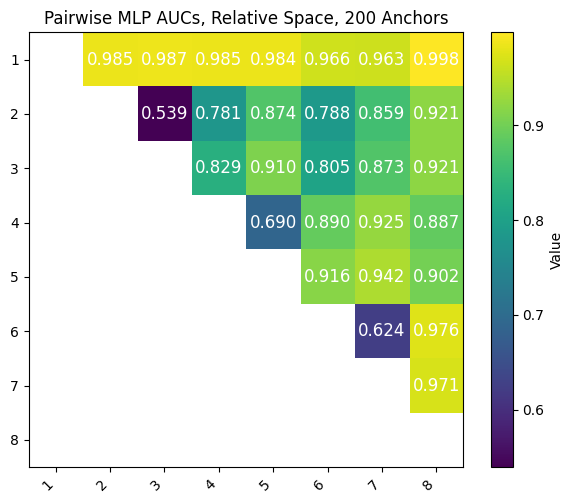

In [11]:
A = classification_aucs_200.copy()
n = A.shape[0]

# mask: keep only strict upper triangle (k=1), hide everything else
mask = np.triu(np.ones_like(A, dtype=bool), k=1)
plot_A = np.where(mask, A, np.nan)

# color range: min non-zero to max over the visible (unmasked) cells
vals = plot_A[~np.isnan(plot_A)]
nonzero = vals[vals != 0]
vmin, vmax = float(nonzero.min()), float(nonzero.max())

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color=(1,1,1,0))  # transparent for masked cells

im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# axes and labels
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels([f"{i+1}" for i in range(n)], rotation=45, ha="right")
ax.set_yticklabels([f"{i+1}" for i in range(n)])
ax.set_title("Pairwise MLP AUCs, Relative Space, 200 Anchors")

# colorbar (uses the vmin/vmax above, so no zeros)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

# annotate only the strict upper triangle
for i in range(n):
    for j in range(i+1, n):
        ax.text(j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=12, color="w")

plt.tight_layout()
plt.show()

In [ ]:
classification_aucs_20 = np.zeros((8, 8))
for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
    self_matrix_1_file = f"../../medium_w2/w2_block_{i}_{i}.npy"
    self_matrix_2_file = f"../../medium_w2/w2_block_{j}_{j}.npy"
    off_diag_matrix_file = f"../../medium_w2/w2_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=10, seed=42
    )

    y = np.r_[np.zeros(4000, dtype=int), np.ones(4000, dtype=int)]

    # Train/test split (stratified)
    X_train, X_test, y_train, y_test = train_test_split(
        rel_reps, y, test_size=0.2, stratify=y, random_state=42
    )

    # --- PyTorch MLP instead of sklearn GridSearch ---
    auc, _ = train_eval_mlp_torch(
        X_train,
        y_train,
        X_test,
        y_test,
        hidden=(128, 64),
        lr=1e-4,
        weight_decay=1e-4,
        batch_size=256,
        max_epochs=100,
        patience=10,
        val_size=0.1,
        seed=42,
        verbose=False,  # set True if you want per-epoch logs
    )

    classification_aucs_20[i, j] = auc

In [ ]:
A = classification_aucs_20.copy()
n = A.shape[0]

# mask: keep only strict upper triangle (k=1), hide everything else
mask = np.triu(np.ones_like(A, dtype=bool), k=1)
plot_A = np.where(mask, A, np.nan)

# color range: min non-zero to max over the visible (unmasked) cells
vals = plot_A[~np.isnan(plot_A)]
nonzero = vals[vals != 0]
vmin, vmax = float(nonzero.min()), float(nonzero.max())

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color=(1,1,1,0))  # transparent for masked cells

im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# axes and labels
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels([f"{i+1}" for i in range(n)], rotation=45, ha="right")
ax.set_yticklabels([f"{i+1}" for i in range(n)])
ax.set_title("Pairwise MLP AUCs, Relative Space, 20 Anchors")

# colorbar (uses the vmin/vmax above, so no zeros)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

# annotate only the strict upper triangle
for i in range(n):
    for j in range(i+1, n):
        ax.text(j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=8, color="w")

plt.tight_layout()
plt.show()

In [ ]:
classification_aucs_2 = np.zeros((8, 8))
for i, j in tqdm(combinations(range(8), 2), total=len(list(combinations(range(8), 2)))):
    self_matrix_1_file = f"../../medium_w2/w2_block_{i}_{i}.npy"
    self_matrix_2_file = f"../../medium_w2/w2_block_{j}_{j}.npy"
    off_diag_matrix_file = f"../../medium_w2/w2_block_{i}_{j}.npy"

    big_matrix = ot_utils.combine_distance_blocks(
        [self_matrix_1_file, off_diag_matrix_file, self_matrix_2_file]
    )

    labels = np.repeat([0, 1], 4000)

    rel_reps = comparison_utils.relative_rep(
        big_matrix, labels, num_classes=2, anchors_per_class=1, seed=42
    )

    y = np.r_[np.zeros(4000, dtype=int), np.ones(4000, dtype=int)]

    # Train/test split (stratified)
    X_train, X_test, y_train, y_test = train_test_split(
        rel_reps, y, test_size=0.2, stratify=y, random_state=42
    )

    # --- PyTorch MLP instead of sklearn GridSearch ---
    auc, _ = train_eval_mlp_torch(
        X_train,
        y_train,
        X_test,
        y_test,
        hidden=(128, 64),
        lr=1e-4,
        weight_decay=1e-4,
        batch_size=256,
        max_epochs=100,
        patience=10,
        val_size=0.1,
        seed=42,
        verbose=False,  # set True if you want per-epoch logs
    )

    classification_aucs_2[i, j] = auc

In [ ]:
A = classification_aucs_2.copy()
n = A.shape[0]

# mask: keep only strict upper triangle (k=1), hide everything else
mask = np.triu(np.ones_like(A, dtype=bool), k=1)
plot_A = np.where(mask, A, np.nan)

# color range: min non-zero to max over the visible (unmasked) cells
vals = plot_A[~np.isnan(plot_A)]
nonzero = vals[vals != 0]
vmin, vmax = float(nonzero.min()), float(nonzero.max())

fig, ax = plt.subplots(figsize=(6, 5))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color=(1,1,1,0))  # transparent for masked cells

im = ax.imshow(plot_A, cmap=cmap, vmin=vmin, vmax=vmax)

# axes and labels
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels([f"{i+1}" for i in range(n)], rotation=45, ha="right")
ax.set_yticklabels([f"{i+1}" for i in range(n)])
ax.set_title("Pairwise MLP AUCs, Relative Space, 2 Anchors")

# colorbar (uses the vmin/vmax above, so no zeros)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Value")

# annotate only the strict upper triangle
for i in range(n):
    for j in range(i+1, n):
        ax.text(j, i, f"{A[i, j]:.3f}", ha="center", va="center", fontsize=8, color="w")

plt.tight_layout()
plt.show()

In [ ]:
M1 = classification_aucs_2

M2 = classification_aucs_20

M3 = classification_aucs_200

matrices = [M1, M2, M3]
titles = [
    "Pairwise MLP AUCs, Relative Space, 200 Anchors",
    "Pairwise MLP AUCs, Relative Space, 20 Anchors",
    "Pairwise MLP AUCs, Relative Space, 2 Anchors"
]

# Mask diagonal + lower triangle
masked = [np.ma.masked_where(~np.triu(np.ones_like(M), k=1).astype(bool), M) for M in matrices]

# Compute global vmin/vmax excluding zeros
all_values = np.concatenate([M[np.triu_indices_from(M, k=1)] for M in matrices])
all_values = all_values[all_values > 0]   # remove zeros
vmin, vmax = all_values.min(), all_values.max()

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
cmap = plt.cm.viridis

for ax, mat, title in zip(axes, masked, titles):
    im = ax.imshow(mat, vmin=vmin, vmax=vmax, cmap=cmap)
    # annotate values
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if i < j:
                ax.text(j, i, f"{mat.data[i,j]:.3f}", ha="center", va="center",
                        color="black", fontsize=7)
    ax.set_title(title)
    ax.set_xticks(range(8))
    ax.set_yticks(range(8))
    ax.set_xticklabels(range(1, 9))
    ax.set_yticklabels(range(1, 9))

# Shared colorbar
cbar = fig.colorbar(im, ax=axes, orientation="vertical", fraction=0.02, pad=0.04)
cbar.set_label("Value")
cbar.set_ticks(np.linspace(vmin, vmax, 6))

plt.show()